# Martinez-Jimenez: activated CD4+T cells
In this work, they analyze unstimulated and stimulated naïve and effector memory CD4+ T cells from young (3 months) and old (21 months) mice of two different strains. 

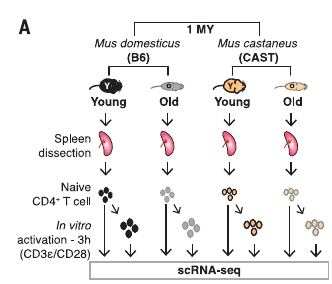

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
import scanpy.external as sce
import scallop as sl
import anndata
import seaborn as sns
import os
import subprocess
import xlrd
import random
import scipy.stats as stats

In [4]:
safe = ['#88CCEE','#CC6677', '#DDCC77','#117733','#332288','#AA4499','#44AA99','#999933','#882255','#661100','#6699CC','#888888']
bold_and_vivid = ['#7F3C8D','#11A579','#3969AC','#F2B701','#E73F74','#80BA5A','#E68310','#008695','#CF1C90',
           '#f97b72','#4b4b8f', '#E58606','#5D69B1','#52BCA3','#99C945','#CC61B0','#24796C','#DAA51B',
           '#2F8AC4','#764E9F','#ED645A','#CC3A8E']
large = safe+bold_and_vivid
mute = sns.color_palette('muted')
seed = 10

In [5]:
name_dataset = 'Martinez-Jimenez'

In [8]:
os.path.exists('../../data/raw_data/martinez-jimenez/')

True

In [10]:
cd ../../data/raw_data/martinez-jimenez

/media/amon/2TB-HD/Olga/scallop-notebooks/scallop-notebooks/scallop_biological/scallop_directory/data/raw_data/martinez-jimenez


## Download data

In [ ]:
url_norm_data = 'https://raw.githubusercontent.com/MarioniLab/ImmuneAging2017/master/Data/normalized_data.txt'
url_raw_data = 'https://raw.githubusercontent.com/MarioniLab/ImmuneAging2017/master/Data/raw_data.txt'
url_metadata = 'https://github.com/MarioniLab/ImmuneAging2017/blob/master/Data/metadata.xlsx'

for url in (url_norm_data, url_raw_data, url_metadata):
    subprocess.run([f'wget {url}', ], shell=True, check=True)

In [22]:
ls

Beta_cells_pairwise_euclidean_distance.csv
Enge.ipynb
Enge_preprocessing.ipynb
Enge_transcriptional_noise.ipynb
Lung_datasets_Enge_methods.ipynb
Martinez_Jimenez_preprocessing.ipynb
Martinez-Jimenez_transcriptional_noise.ipynb
__pycache__/


In [11]:
# adata_all = sc.read('normalized_data.txt', delimiter='\t').transpose()
adata_all = sc.read('raw_data.txt', delimiter='\t').transpose()

In [14]:
metadata = pd.read_excel('metadata.xlsx', engine="openpyxl", index_col=6)

/home/amon/anaconda3/lib/python3.7/site-packages/openpyxl/styles/stylesheet.py:221: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [15]:
metadata

,Unnamed: 0,Strain,Age,Stimulus,Individuals,Celltype
CellName,,,,,,
SS19_naive_2,do4737,Mus musculus castaneus,Young,Unstimulated,CAST young 1,MACS-purified Naive
SS19_naive_96,do4739,Mus musculus castaneus,Young,Unstimulated,CAST young 1,MACS-purified Naive
SS19_naive_95,do4740,Mus musculus castaneus,Young,Unstimulated,CAST young 1,MACS-purified Naive
SS19_naive_4,do4744,Mus musculus castaneus,Young,Unstimulated,CAST young 1,MACS-purified Naive
SS19_naive_89,do4752,Mus musculus castaneus,Young,Unstimulated,CAST young 1,MACS-purified Naive
...,...,...,...,...,...,...
SS59_active_42,do7543,Mus musculus domesticus,Old,Activated,B6 old 10,MACS-purified Naive
SS59_active_57,do7546,Mus musculus domesticus,Old,Activated,B6 old 10,MACS-purified Naive
SS59_active_44,do7548,Mus musculus domesticus,Old,Activated,B6 old 10,MACS-purified Naive


In [16]:
cd ../../../notebooks

/media/amon/2TB-HD/Olga/scallop-notebooks/scallop-notebooks/scallop_biological/scallop_directory/notebooks


In [17]:
ercc = [var for var in adata_all.var_names if var.upper().startswith('ERCC-')]

In [23]:
mouse_genes = pd.read_csv('../data/raw_data/martinez-jimenez/Mm_illumina_features.txt', sep='\t', index_col=0)

In [24]:
gene_dic = dict(mouse_genes.loc[:, 'Gene name'])

In [25]:
len(gene_dic)

56305

In [26]:
for spikein in ercc: 
    gene_dic[spikein] = spikein

In [27]:
adata_all = adata_all[:, list(set(adata_all.var_names).intersection(set(gene_dic.keys())))]

In [28]:
new_names = [gene_dic[gene] if gene in adata_all.var_names else gene for gene in adata_all.var_names ]

In [29]:
adata_all.var_names = new_names

# Preprocessing

In [30]:
adata_all.obs['age'] = metadata['Age']
adata_all.obs['strain'] = metadata['Strain']
adata_all.obs['stimulus'] = metadata['Stimulus']
adata_all.obs['individuals'] = metadata['Individuals']
adata_all.obs['celltype'] = metadata['Celltype']

In [31]:
sc.pp.filter_cells(adata_all, min_genes=200)
sc.pp.filter_genes(adata_all, min_cells=3)
adata_all.var_names_make_unique()
sc.pp.normalize_total(adata_all, target_sum=1e4)
sc.pp.log1p(adata_all)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [32]:
def preprocessing(adata, batch_correction, batch_category):
    sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=5, min_disp=0.3)
    sc.pp.pca(adata)
    if batch_correction == 'bbknn':
        sce.pp.bbknn(adata, batch_key=batch_category)
    elif batch_correction == 'harmony':
        sce.pp.harmony_integrate(adata, batch_category)
        sc.pp.neighbors(adata,use_rep='X_pca_harmony')
    sc.tl.umap(adata)
    return adata


In [201]:
adata_all = preprocessing(adata_all, batch_correction='bbknn', batch_category='strain')

In [ ]:
adata_all.write('../data/anndatas/annotated/Martinez-Jimenez.h5ad')